# Guia Completo de Visualização de Dados para Ciência de Dados
**Disciplina:** Ferramentas para Data Science  
**Bibliotecas:** `pandas`, `seaborn`, `matplotlib`  

---  
## Sumário de Gráficos
1. **Comparação & Categorias:** Barras Horizontais, Colunas Verticais, Barras Empilhadas
2. **Evolução Temporal & Tendência:** Linhas, Área Acumulada, Spline (Suavizado)
3. **Distribuições:** Histograma, Boxplot, Curva KDE
4. **Relações & Correlações:** Dispersão (Scatter Plot), Bolhas (Bubble Chart), Pairplot
5. **Composição & Proporção:** Treemap, Rosca (Donut)

In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.interpolate import make_interp_spline
import squarify  # Para criação do Treemap

# Configurações estéticas globais
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

## 1. Carregar, Preparar e Explorar os Dados:

In [36]:
# Carregando dataset:
df = pd.read_csv('dados_investimento_e_vagas_ifes.csv')

df.head()

df.describe()

,ano,investimento_total_ifes_bilhoes_brl,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,num_terceirizados
count,31.000000,31.000000,31.000000,3.100000e+01,31.000000,31.000000,31.000000
mean,2011.000000,53.019355,0.693548,8.967581e+05,64316.129032,61212.903226,34812.903226
std,9.092121,15.830802,0.534749,4.008678e+05,28928.787240,14261.410448,18120.425711
min,1996.000000,29.800000,0.020000,3.421000e+05,26800.000000,41500.000000,8200.000000
25%,2003.500000,34.350000,0.070000,4.659500e+05,30650.000000,43800.000000,14300.000000
50%,2011.000000,54.100000,0.920000,9.845000e+05,73100.000000,69800.000000,41200.000000
75%,2018.500000,65.950000,1.210000,1.305000e+06,92850.000000,73150.000000,48850.000000
max,2026.000000,76.500000,1.320000,1.385000e+06,98100.000000,77400.000000,59100.000000


In [37]:
## 2. Evolução Temporal e Ajuste de Escalas (Tomada de Decisão):

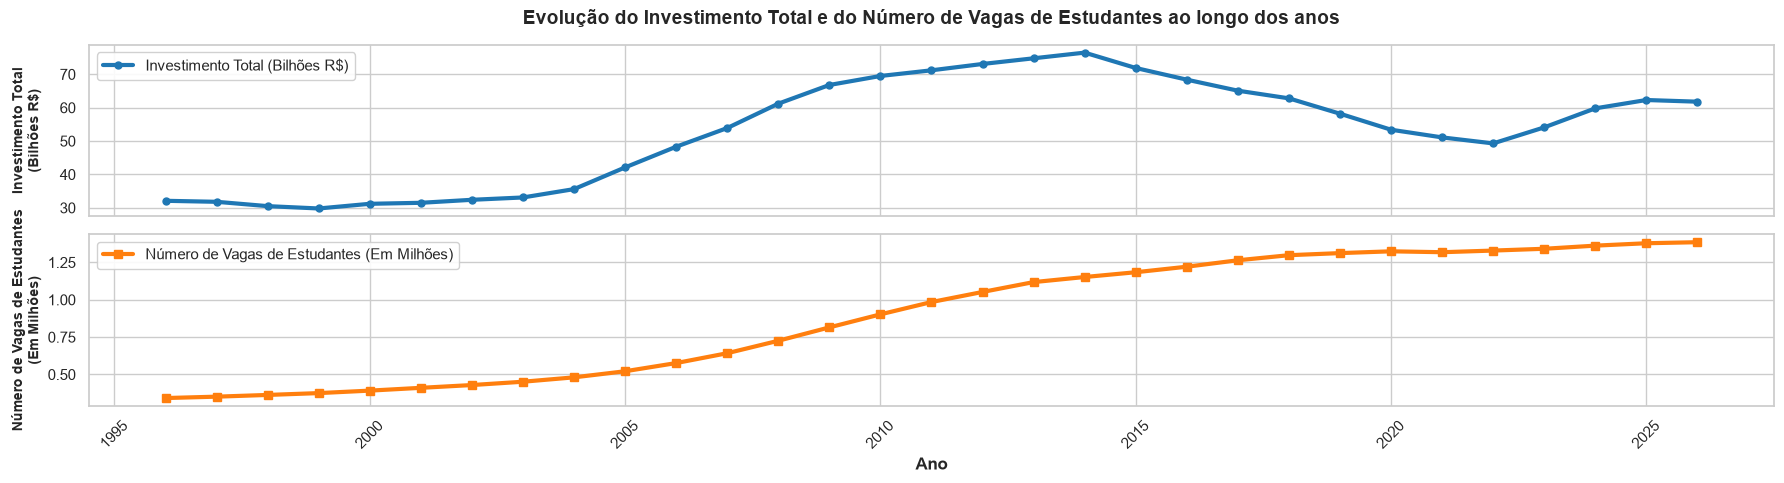

In [81]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 5), sharex=True)

# Agrupando por ano:
groups = df.groupby('ano')[['investimento_total_ifes_bilhoes_brl', 'num_vagas_estudantes']].sum().reset_index()

# Gráfico Superior - Investimento Total:
ax1.plot(groups['ano'], groups['investimento_total_ifes_bilhoes_brl'], marker='o', markersize=5, linewidth=3, label='Investimento Total (Bilhões R$)', color='#1f77b4')
ax1.set_ylabel('Investimento Total\n(Bilhões R$)', fontsize=10, fontweight='bold')
ax1.yaxis.set_major_locator(MultipleLocator(10))
ax1.tick_params(axis='x', rotation=45)

ax1.set_title('Evolução do Investimento Total e do Número de Vagas de Estudantes ao longo dos anos', fontsize=14, fontweight='bold', pad=15)

ax1.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# Gráfico Inferior - Número de Vagas de Estudantes:
ax2.plot(groups['ano'], groups['num_vagas_estudantes'] / 1e6, marker='s', linewidth=3, label='Número de Vagas de Estudantes (Em Milhões)', color='#ff7f0e')
ax2.set_xlabel('Ano', fontsize=12, fontweight='bold')
ax2.set_ylabel('Número de Vagas de Estudantes\n(Em Milhões)', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)

ax2.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

fig.align_ylabels([ax1, ax2])

plt.tight_layout()

plt.show()

## 3. Análise de Proporção de Força de Trabalho (Docentes vs. TAEs):

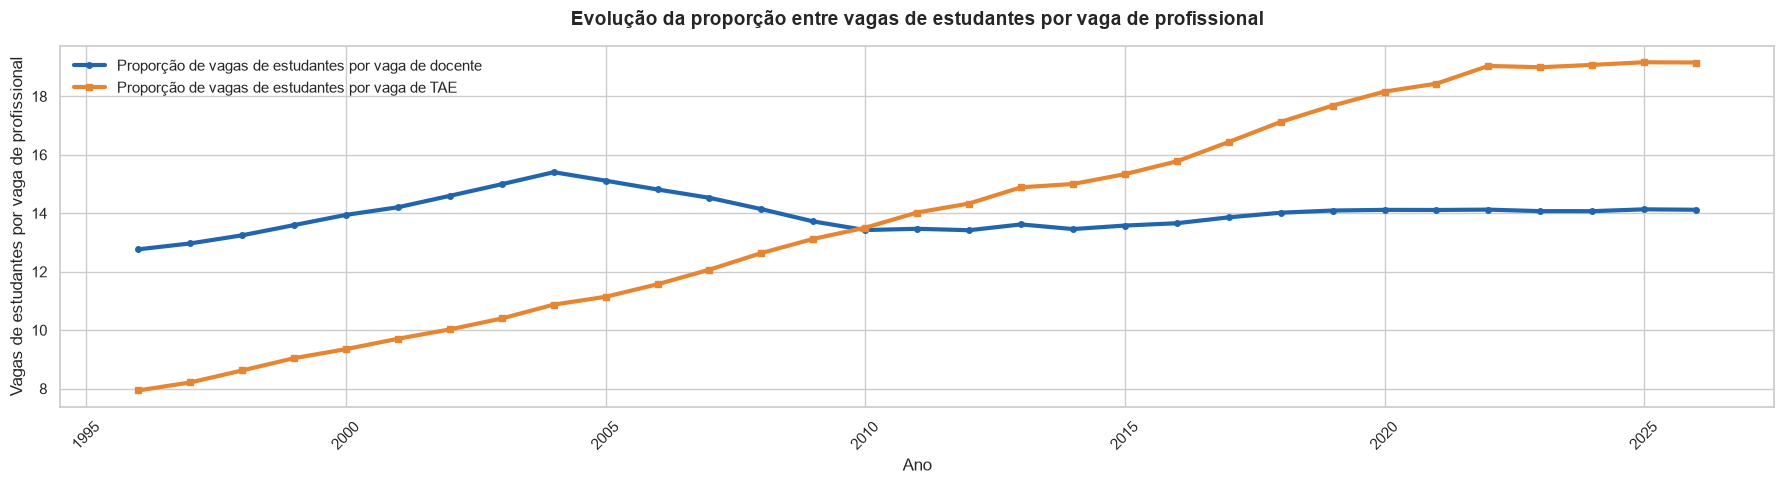

In [87]:
# Proporção de vagas de estudantes por vaga de docente:
df['proporcao_estudante_docente'] = (
    df['num_vagas_estudantes'] / df['num_vagas_docente']
    )

# Proporção de vagas de estudantes por vaga de Técnico-Administrativo em Educação (TAE):
df['proporcao_estudante_tae'] = (
    df['num_vagas_estudantes'] / df['num_vagas_tae']
    )

df[['ano', 'proporcao_estudante_docente', 'proporcao_estudante_tae']].head()

fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(df['ano'], df['proporcao_estudante_docente'], marker='o', markersize=4, linewidth=3, label='Proporção de vagas de estudantes por vaga de docente', color='#2166AC')
ax.plot(df['ano'], df['proporcao_estudante_tae'], marker='s', markersize=4, linewidth=3, label='Proporção de vagas de estudantes por vaga de TAE', color='#E68632')

ax.set_title('Evolução da proporção entre vagas de estudantes por vaga de profissional', fontsize=14, fontweight='bold', pad=15)

ax.set_xlabel('Ano')
ax.set_ylabel('Vagas de estudantes por vaga de profissional')

ax.tick_params(axis='x', rotation=45)
ax.legend(loc='best', frameon=False)

plt.tight_layout()

plt.show()

### 1.2 Barras Empilhadas (Stacked Bars)

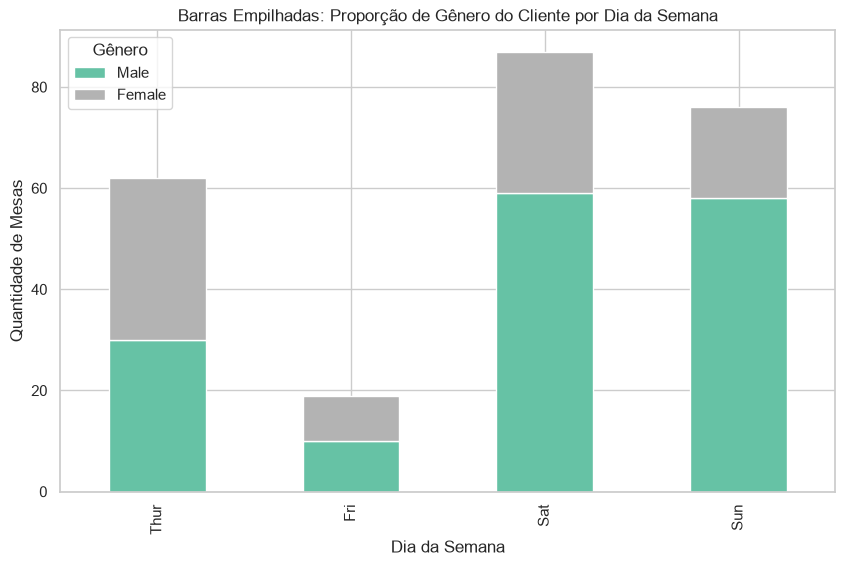

In [71]:
tips = sns.load_dataset('tips')
stacked_data = pd.crosstab(tips['day'], tips['sex'])

stacked_data.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2')
plt.title('Barras Empilhadas: Proporção de Gênero do Cliente por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Quantidade de Mesas')
plt.legend(title='Gênero')
plt.show()

---  
## 2. Evolução Temporal e Tendência

### 2.1 Linhas, Área Acumulada e Spline Suavizado

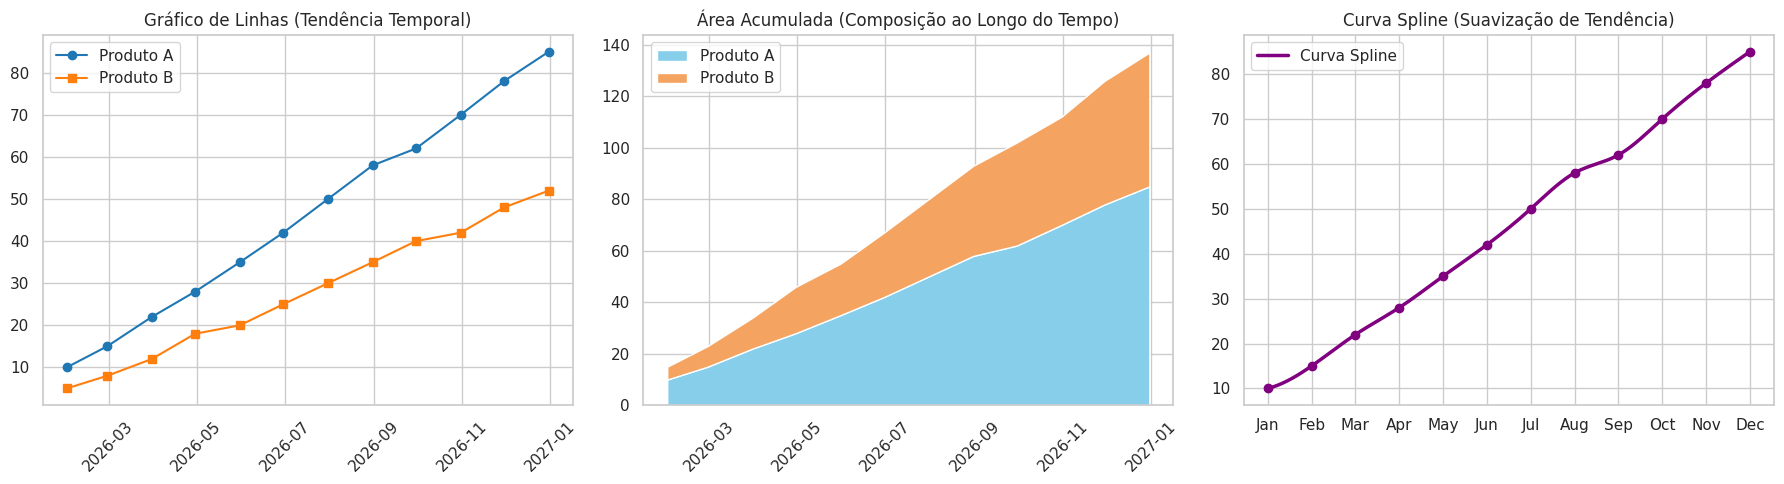

In [ ]:
# Criando dados sintéticos temporais
np.random.seed(42)
datas = pd.date_range(start='2026-01-01', periods=12, freq='ME')
vendas_A = np.array([10, 15, 22, 28, 35, 42, 50, 58, 62, 70, 78, 85])
vendas_B = np.array([5, 8, 12, 18, 20, 25, 30, 35, 40, 42, 48, 52])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Gráfico de Linhas
axes[0].plot(datas, vendas_A, marker='o', label='Produto A', color='tab:blue')
axes[0].plot(datas, vendas_B, marker='s', label='Produto B', color='tab:orange')
axes[0].set_title('Gráfico de Linhas (Tendência Temporal)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# 2. Área Acumulada (Stacked Area)
axes[1].stackplot(datas, vendas_A, vendas_B, labels=['Produto A', 'Produto B'], colors=['skyblue', 'sandybrown'])
axes[1].set_title('Área Acumulada (Composição ao Longo do Tempo)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(loc='upper left')

# 3. Spline Suavizado
x_numeric = np.arange(len(datas))
x_smooth = np.linspace(x_numeric.min(), x_numeric.max(), 200)
spl = make_interp_spline(x_numeric, vendas_A, k=3)
y_smooth = spl(x_smooth)

axes[2].plot(x_smooth, y_smooth, color='purple', linewidth=2.5, label='Curva Spline')
axes[2].scatter(x_numeric, vendas_A, color='purple')
axes[2].set_title('Curva Spline (Suavização de Tendência)')
axes[2].set_xticks(x_numeric)
axes[2].set_xticklabels([d.strftime('%b') for d in datas])
axes[2].legend()

plt.tight_layout()
plt.show()

---  
## 3. Distribuições

### 3.1 Histograma, Boxplot e Curva KDE

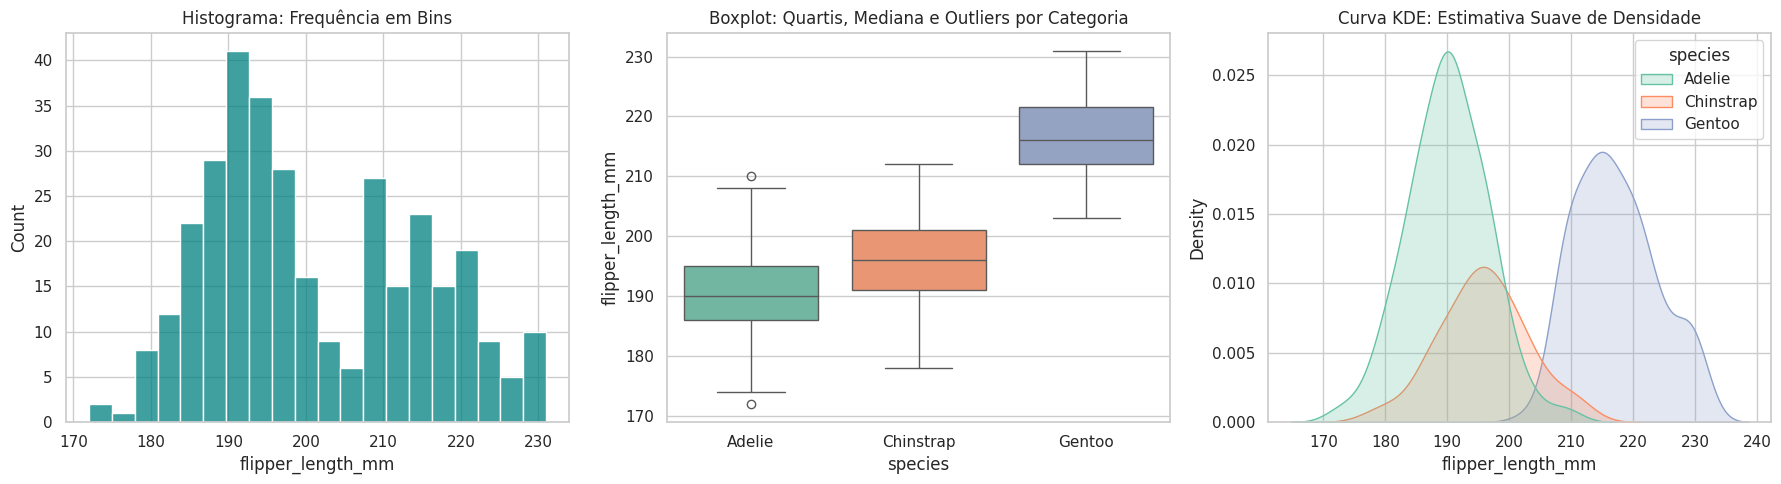

In [ ]:
penguins = sns.load_dataset('penguins').dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma
sns.histplot(data=penguins, x='flipper_length_mm', bins=20, ax=axes[0], color='teal')
axes[0].set_title('Histograma: Frequência em Bins')

# Boxplot
sns.boxplot(data=penguins, x='species', y='flipper_length_mm', hue='species', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('Boxplot: Quartis, Mediana e Outliers por Categoria')

# Curva KDE
sns.kdeplot(data=penguins, x='flipper_length_mm', hue='species', fill=True, ax=axes[2], palette='Set2')
axes[2].set_title('Curva KDE: Estimativa Suave de Densidade')

plt.tight_layout()
plt.show()

---  
## 4. Relações e Correlações

### 4.1 Scatter Plot, Gráfico de Bolhas e Pairplot

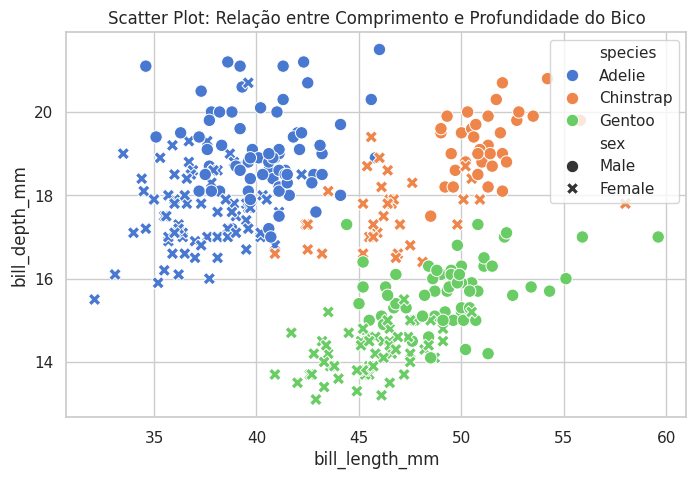

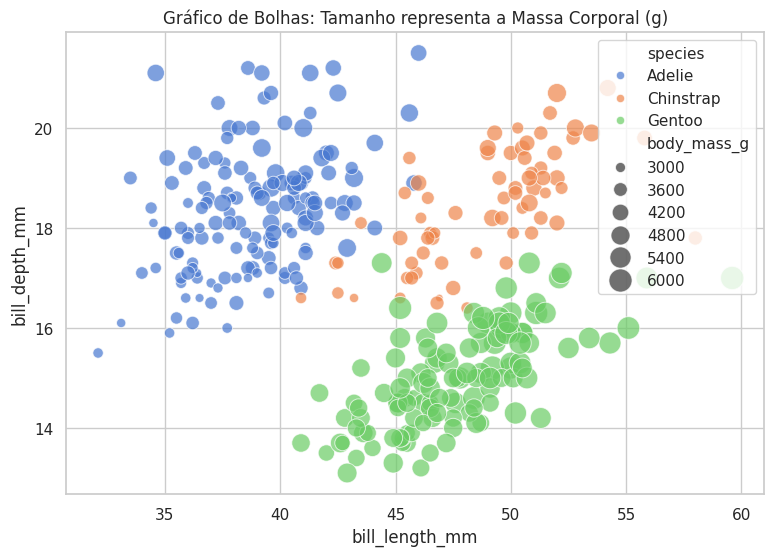

In [ ]:
# Dispersão (Scatter Plot)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species', style='sex', s=80)
plt.title('Scatter Plot: Relação entre Comprimento e Profundidade do Bico')
plt.show()

# Gráfico de Bolhas (Scatter Plot com 'size')
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=penguins,
    x='bill_length_mm',
    y='bill_depth_mm',
    size='body_mass_g',
    hue='species',
    sizes=(30, 300),
    alpha=0.7
)
plt.title('Gráfico de Bolhas: Tamanho representa a Massa Corporal (g)')
plt.show()

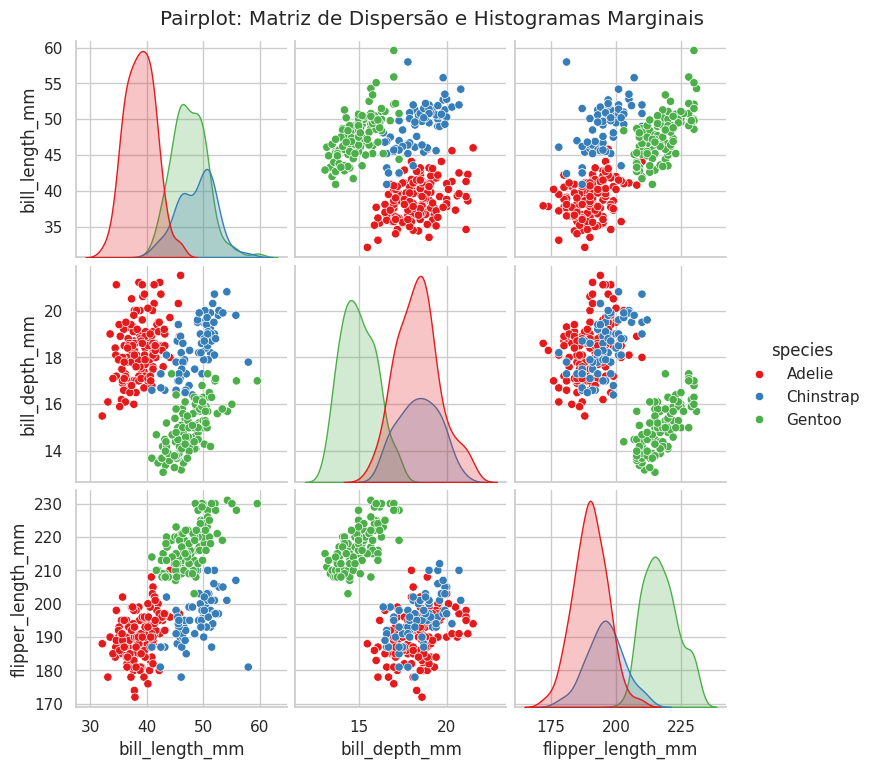

In [ ]:
# Pairplot (Matriz de Dispersão para múltiplas variáveis)
sns.pairplot(penguins, hue='species', vars=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm'], palette='Set1')
plt.suptitle('Pairplot: Matriz de Dispersão e Histogramas Marginais', y=1.02)
plt.show()

---  
## 5. Composição e Proporção

### 5.1 Treemap e Gráfico de Rosca (Donut Chart)

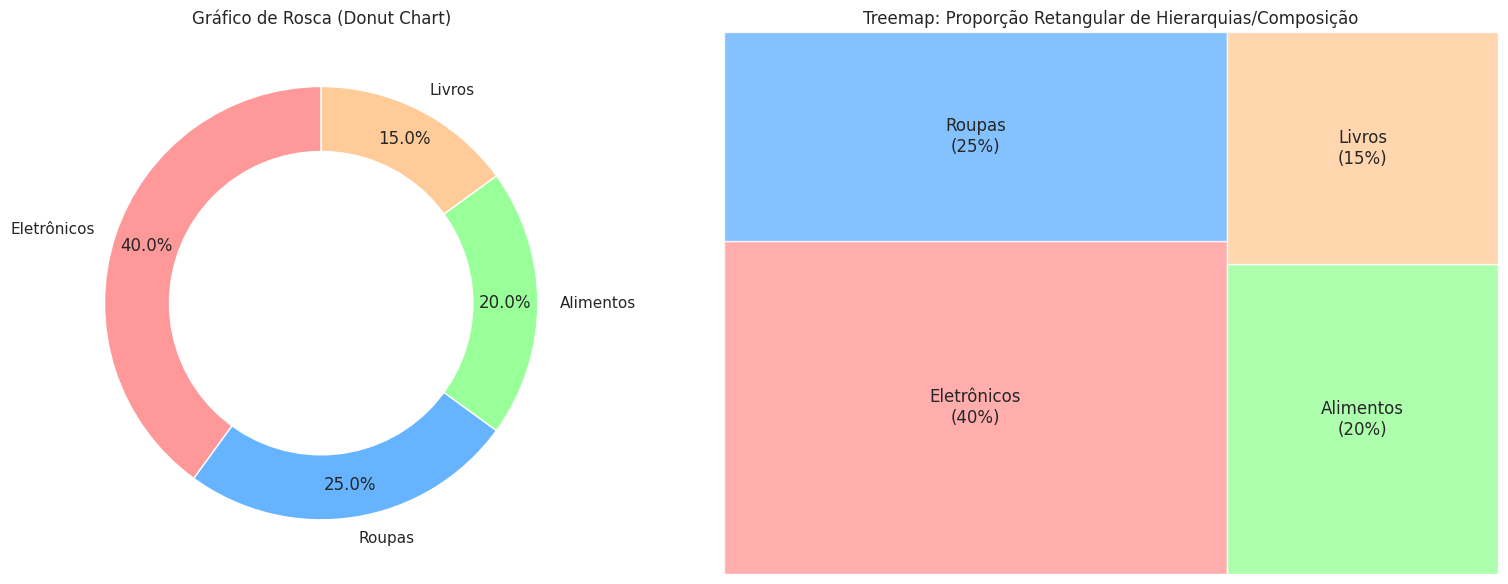

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de Rosca (Donut)
categorias = ['Eletrônicos', 'Roupas', 'Alimentos', 'Livros']
valores = [40, 25, 20, 15]
cores = ['#ff9999','#66b3ff','#99ff99','#ffcc99']

axes[0].pie(valores, labels=categorias, autopct='%1.1f%%', startangle=90, colors=cores, pctdistance=0.85)
# Criando o centro branco para transformar pizza em rosca
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
axes[0].add_artist(centre_circle)
axes[0].set_title('Gráfico de Rosca (Donut Chart)')

# 2. Treemap
rotulos_treemap = [f'{cat}\n({val}%)' for cat, val in zip(categorias, valores)]
squarify.plot(sizes=valores, label=rotulos_treemap, color=cores, alpha=0.8, ax=axes[1])
axes[1].set_title('Treemap: Proporção Retangular de Hierarquias/Composição')
axes[1].axis('off')

plt.tight_layout()
plt.show()